In [ ]:
import torch
print(torch.cuda.is_available())
torch.manual_seed(0)

True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp "/content/drive/MyDrive/SER/Emociones.zip" /content/
!unzip -q -o /content/Emociones.zip -d /content/Emociones
!ls /content/Emociones

Podcast


In [ ]:
import torchaudio
import soundfile as sf
import pandas as pd

CARPETA = "/content/Emociones/Podcast/"
etiquetas = pd.read_csv(CARPETA + "labels.csv")
MAX_LEN = 1377
N_MELS = 30

mel = torchaudio.transforms.MelSpectrogram(
    sample_rate=16000,
    n_fft=256,
    n_mels=N_MELS)

In [ ]:
X = torch.zeros(len(etiquetas), MAX_LEN, N_MELS)
largos = torch.zeros(len(etiquetas), dtype=torch.long)

for i in range(len(etiquetas)):
    datos, fs = sf.read(CARPETA + etiquetas["path"][i], dtype="float32")
    espectro = torch.log(mel(torch.from_numpy(datos)) + 1e-9)
    espectro = espectro.T
    largos[i] = espectro.shape[0]
    X[i, :largos[i]] = espectro

Y = torch.tensor(etiquetas[["activation", "valence", "dominance"]].values, dtype=torch.float32)
particion = etiquetas["partition"].values

print(X.shape, largos.min().item(), largos.max().item())

torch.Size([6000, 1377, 30]) 241 1377


In [ ]:
es_train = torch.tensor(particion == "train")
mascara = torch.arange(MAX_LEN)[None, :] >= largos[:, None]

tramas_train = X[es_train][~mascara[es_train]]
media_X = tramas_train.mean(dim=0)
desv_X = tramas_train.std(dim=0)

X = (X - media_X) / desv_X
X[mascara] = 0

print(X[es_train][~mascara[es_train]].mean().item(),
      X[es_train][~mascara[es_train]].std().item())

-4.9631241338943255e-09 0.9999998211860657


In [ ]:
media_Y = Y[es_train].mean(dim=0)
desv_Y = Y[es_train].std(dim=0)
Y_norm = (Y - media_Y) / desv_Y

print(media_Y, desv_Y)

tensor([4.4851, 3.9211, 4.5854]) tensor([0.9946, 1.0403, 0.9531])


In [ ]:
import math
from torch import nn

class ModeloSER(nn.Module):
    def __init__(self, d=50, cabezas=5):
        super().__init__()

        self.proyeccion = nn.Linear(N_MELS, d)
        self.cls = nn.Parameter(torch.randn(1, 1, d))

        pos = torch.arange(MAX_LEN + 1).unsqueeze(1)
        frec = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe = torch.zeros(MAX_LEN + 1, d)
        pe[:, 0::2] = torch.sin(pos * frec)
        pe[:, 1::2] = torch.cos(pos * frec)
        self.register_buffer("pe", pe)

        self.encoder = nn.TransformerEncoderLayer(
            d_model=d, nhead=cabezas, dim_feedforward=d,
            batch_first=True)

        self.salida = nn.Sequential(
            nn.Linear(d, d), nn.ReLU(), nn.Linear(d, 3))

    def forward(self, x, mascara):
        B = x.shape[0]
        x = self.proyeccion(x)
        x = torch.cat([self.cls.expand(B, -1, -1), x], dim=1)
        x = x + self.pe
        sin_relleno = torch.zeros(B, 1, dtype=torch.bool, device=x.device)
        mascara = torch.cat([sin_relleno, mascara], dim=1)
        x = self.encoder(x, src_key_padding_mask=mascara)
        return self.salida(x[:, 0])

In [ ]:
dispositivo = "cuda"
modelo = ModeloSER().to(dispositivo)
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

x = X[es_train][:32].to(dispositivo)
m = mascara[es_train][:32].to(dispositivo)
y = Y_norm[es_train][:32].to(dispositivo)

for paso in range(300):
    optimizador.zero_grad()
    error = ((modelo(x, m) - y) ** 2).mean()
    error.backward()
    optimizador.step()
    if paso % 50 == 0:
        print(paso, error.item())

0 1.189125657081604
50 0.4620460271835327
100 0.08235017955303192
150 0.02971745654940605
200 0.022929882630705833
250 0.013324780389666557


In [ ]:
es_val = torch.tensor(particion == "validation")
idx_train = torch.where(es_train)[0]
idx_val = torch.where(es_val)[0]

def error_en(indices):
    modelo.eval()
    suma = 0
    with torch.no_grad():
        for inicio in range(0, len(indices), 32):
            lote = indices[inicio:inicio + 32]
            pred = modelo(X[lote].to(dispositivo), mascara[lote].to(dispositivo))
            suma += ((pred - Y_norm[lote].to(dispositivo)) ** 2).sum().item()
    return suma / (len(indices) * 3)

In [ ]:
modelo = ModeloSER().to(dispositivo)
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-4)
ARCHIVO = f"/content/drive/MyDrive/SER/mejor_modelo_{N_MELS}mel.pt"

mejor_val = 999
paciencia = 0
hist_train, hist_val = [], []

for epoca in range(100):
    modelo.train()
    orden = idx_train[torch.randperm(len(idx_train))]
    errores = []

    for inicio in range(0, len(orden), 32):
        lote = orden[inicio:inicio + 32]
        optimizador.zero_grad()
        pred = modelo(X[lote].to(dispositivo), mascara[lote].to(dispositivo))
        error = ((pred - Y_norm[lote].to(dispositivo)) ** 2).mean()
        error.backward()
        optimizador.step()
        errores.append(error.item())

    e_train = sum(errores) / len(errores)
    e_val = error_en(idx_val)
    hist_train.append(e_train)
    hist_val.append(e_val)
    print(epoca + 1, round(e_train, 4), round(e_val, 4))

    if e_val < mejor_val:
        mejor_val = e_val
        paciencia = 0
        torch.save(modelo.state_dict(), ARCHIVO)
    else:
        paciencia += 1
        if paciencia == 10:
            break

1 0.9959 0.9744
2 0.9426 0.9371
3 0.9139 0.9179
4 0.8997 0.887
5 0.8829 0.874
6 0.876 0.8609
7 0.8765 0.8568
8 0.8692 0.8517
9 0.8666 0.8488
10 0.8651 0.845
11 0.8637 0.8396
12 0.8641 0.8529
13 0.8592 0.8377
14 0.8546 0.8434
15 0.8534 0.8269
16 0.8523 0.8291
17 0.8516 0.8249
18 0.8432 0.8171
19 0.8388 0.8162
20 0.8374 0.8216
21 0.841 0.8103
22 0.8289 0.8074
23 0.8298 0.8019
24 0.8297 0.8079
25 0.821 0.8148
26 0.8214 0.8057
27 0.8157 0.7998
28 0.8097 0.7932
29 0.8103 0.7913
30 0.8062 0.7944
31 0.8077 0.7952
32 0.8056 0.8083
33 0.8092 0.8029
34 0.7955 0.7949
35 0.8006 0.7924
36 0.7917 0.7949
37 0.79 0.7927
38 0.7927 0.7932
39 0.7906 0.793


In [ ]:
modelo = ModeloSER().to(dispositivo)
modelo.load_state_dict(torch.load(ARCHIVO))
modelo.eval()

idx_test = torch.where(torch.tensor(particion == "test"))[0]

preds = []
with torch.no_grad():
    for inicio in range(0, len(idx_test), 32):
        lote = idx_test[inicio:inicio + 32]
        preds.append(modelo(X[lote].to(dispositivo), mascara[lote].to(dispositivo)).cpu())

pred = torch.cat(preds) * desv_Y + media_Y
real = Y[idx_test]

mse = ((pred - real) ** 2).mean(dim=0)
mse_dummy = ((media_Y - real) ** 2).mean(dim=0)

print("Modelo:", mse, mse.mean())
print("Dummy :", mse_dummy, mse_dummy.mean())

Modelo: tensor([0.7969, 0.9438, 0.7602]) tensor(0.8336)
Dummy : tensor([1.1060, 1.1375, 0.9663]) tensor(1.0699)


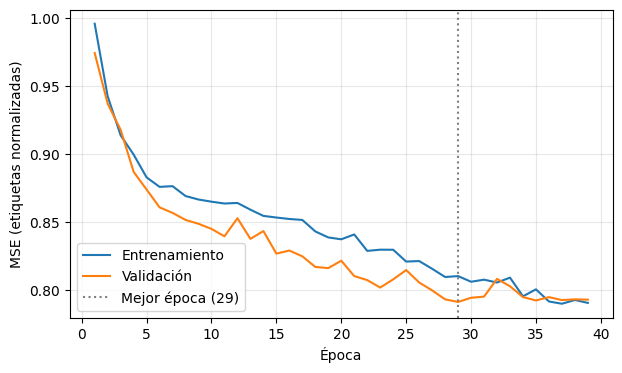

In [ ]:
import matplotlib.pyplot as plt

epocas = range(1, len(hist_train) + 1)
mejor = hist_val.index(min(hist_val)) + 1

plt.figure(figsize=(7, 4))
plt.plot(epocas, hist_train, label="Entrenamiento")
plt.plot(epocas, hist_val, label="Validación")
plt.axvline(mejor, color="gray", linestyle=":", label=f"Mejor época ({mejor})")
plt.xlabel("Época")
plt.ylabel("MSE (etiquetas normalizadas)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(f"/content/drive/MyDrive/SER/curvas_mejorado_{N_MELS}mel.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from IPython.display import Audio, display

dispositivo = "cuda"
modelo = ModeloSER().to(dispositivo)
modelo.load_state_dict(torch.load(ARCHIVO))
modelo.eval()

def predecir(ruta):
    datos, fs = sf.read(ruta, dtype="float32")
    espectro = torch.log(mel(torch.from_numpy(datos)) + 1e-9).T
    espectro = (espectro - media_X) / desv_X
    largo = min(espectro.shape[0], MAX_LEN)
    x = torch.zeros(1, MAX_LEN, N_MELS)
    x[0, :largo] = espectro[:largo]
    m = torch.arange(MAX_LEN)[None, :] >= largo
    with torch.no_grad():
        pred = modelo(x.to(dispositivo), m.to(dispositivo)).cpu()[0]
    return pred * desv_Y + media_Y

ejemplos = etiquetas[etiquetas["partition"] == "test"].sample(5, random_state=0)

for _, fila in ejemplos.iterrows():
    ruta = CARPETA + fila["path"]
    a, v, d = predecir(ruta).tolist()
    print(fila["path"])
    print("  Real:     A", fila["activation"], " V", fila["valence"], " D", fila["dominance"])
    print("  Predicho: A", round(a, 2), " V", round(v, 2), " D", round(d, 2))
    display(Audio(ruta))

test/5834.wav
  Real:     A 6.158  V 6.421  D 5.158
  Predicho: A 4.84  V 4.39  D 4.69


test/5522.wav
  Real:     A 6.2  V 1.2  D 6.4
  Predicho: A 5.11  V 2.69  D 5.26


test/5624.wav
  Real:     A 3.9  V 3.9  D 4.6
  Predicho: A 4.1  V 4.05  D 4.22


test/5879.wav
  Real:     A 5.0  V 5.0  D 4.2
  Predicho: A 3.93  V 3.94  D 4.04


test/5605.wav
  Real:     A 5.6  V 3.5  D 5.65
  Predicho: A 5.46  V 3.85  D 5.35


In [ ]:
def ccc(real, pred):
    mr, mp = real.mean(), pred.mean()
    vr, vp = real.var(unbiased=False), pred.var(unbiased=False)
    cov = ((real - mr) * (pred - mp)).mean()
    return (2 * cov / (vr + vp + (mr - mp) ** 2)).item()

dispositivo = "cuda"
modelo = ModeloSER().to(dispositivo)
modelo.load_state_dict(torch.load("/content/drive/MyDrive/SER/mejor_modelo_30mel.pt"))
modelo.eval()

idx_test = torch.where(torch.tensor(particion == "test"))[0]
preds = []
with torch.no_grad():
    for inicio in range(0, len(idx_test), 32):
        lote = idx_test[inicio:inicio + 32]
        preds.append(modelo(X[lote].to(dispositivo), mascara[lote].to(dispositivo)).cpu())

pred = torch.cat(preds) * desv_Y + media_Y
real = Y[idx_test]
dummy = media_Y.expand(len(idx_test), 3)

print("MSE modelo:", ((pred - real) ** 2).mean(dim=0))
nombres = ["Activation", "Valence", "Dominance"]
for k in range(3):
    print(nombres[k],
          "| CCC modelo:", round(ccc(real[:, k], pred[:, k]), 3),
          "| CCC dummy:", round(ccc(real[:, k], dummy[:, k]), 3))

MSE modelo: tensor([0.7969, 0.9438, 0.7602])
Activation | CCC modelo: 0.411 | CCC dummy: 0.0
Valence | CCC modelo: 0.295 | CCC dummy: -0.0
Dominance | CCC modelo: 0.337 | CCC dummy: 0.0


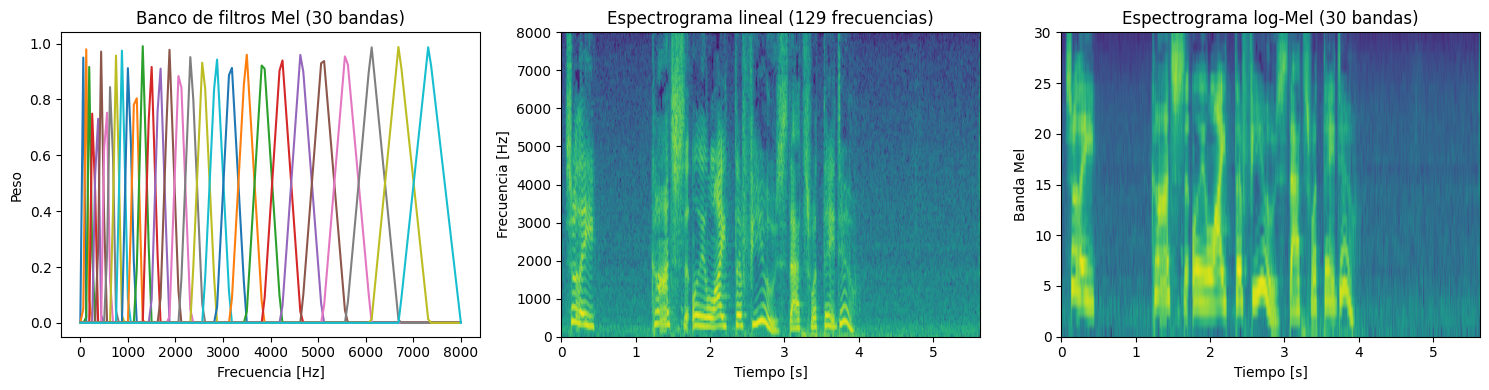

In [ ]:
import matplotlib.pyplot as plt

datos, fs = sf.read(CARPETA + "test/5522.wav", dtype="float32")
señal = torch.from_numpy(datos)
duracion = len(datos) / fs

lineal = torchaudio.transforms.Spectrogram(n_fft=256)(señal)
lineal_db = 10 * torch.log10(lineal + 1e-9)
logmel = torch.log(mel(señal) + 1e-9)
filtros = mel.mel_scale.fb

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(torch.linspace(0, 8000, 129), filtros)
ax[0].set(title="Banco de filtros Mel (30 bandas)", xlabel="Frecuencia [Hz]", ylabel="Peso")
ax[1].imshow(lineal_db, origin="lower", aspect="auto", extent=[0, duracion, 0, 8000])
ax[1].set(title="Espectrograma lineal (129 frecuencias)", xlabel="Tiempo [s]", ylabel="Frecuencia [Hz]")
ax[2].imshow(logmel, origin="lower", aspect="auto", extent=[0, duracion, 0, 30])
ax[2].set(title="Espectrograma log-Mel (30 bandas)", xlabel="Tiempo [s]", ylabel="Banda Mel")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/SER/espectrograma_mel.png", dpi=200, bbox_inches="tight")
plt.show()